# SAMI · Notebook 5 — Which training data: real, Haiku-labelled or synthetic?

**Mandate.** Notebook 4 measured how well a LinearSVC on the pipeline's e5 embeddings reproduces the
client's categories when it is trained on the real development messages. Since then two larger training sets were
built with Claude Haiku: the **full Haiku-labelled dataset** (labels for the messages the client never labelled,
with the human corrections applied) and a set of **synthetic messages** written from real examples (3× the real
messages for the three biggest classes, 10× for the rest). This notebook trains on each, and on mixes, and
scores every variant on **the same frozen test set** as notebook 4, so the two notebooks can be compared line by line. Modules compute (`sami.categorize`), this notebook consumes.

> **Four rules govern every number below.**
>
> 1. **One frozen test set** (588 messages, the one of notebook 4). Each training variant is scored on it once.
>    The variants and the model are fixed *before* looking at any test score: nothing is chosen from the test.
> 2. **No test text in any training set.** Synthetic data is for training only and no synthetic text equals a test
>    text; the same holds for the Haiku-labelled set (asserted). Only synthetic messages whose target class and
>    Haiku's check label *agree* are used, and only Haiku-labelled messages without an unreviewed disagreement.
> 3. **Macro-F1 is the metric**, with accuracy beside it, as in notebook 4.
> 4. **No message text is printed or saved in this notebook.** Outputs are counts, scores and charts.

The test labels are the client's own, so the headline is comparable with notebook 4. A second view scores
the same predictions against the **final** labels (Haiku's labels with the human corrections on top).

In [1]:
import sys, pathlib
# Locate src/ by walking up from the working directory, so `sami` imports whether the kernel starts in
# notebooks/ (JupyterLab) or at the repo root (VS Code).
_cwd = pathlib.Path.cwd()
_src = next((p / "src" for p in (_cwd, *_cwd.parents) if (p / "src" / "sami").is_dir()), None)
if _src is None:
    raise RuntimeError(f"Could not find src/sami/ above {_cwd}. Run this notebook from inside the repository.")
sys.path.insert(0, str(_src))
import warnings
warnings.filterwarnings("ignore")
import time
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.svm import LinearSVC
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, f1_score, accuracy_score
from sklearn.model_selection import StratifiedGroupKFold
from sami import categorize as cz, nlp, theme

ROOT = _src.parent
LABELS = ROOT / "datasets" / "labels"
CACHE = ROOT / "notebooks" / "cache" / "category_embeddings.npz"            # shared with notebook 4
CACHE_SYN = ROOT / "notebooks" / "cache" / "synthetic_embeddings.npz"
MEMO = LABELS / "llm_haiku_synth" / "embeddings.pkl"                        # vectors computed while deduplicating
SRC = "source: MMC client labels + Claude Haiku synthetic messages"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

dev_info = nlp.device_report()
print(f"Compute    : {dev_info['device']} ({dev_info['gpu']}) · torch {dev_info['torch']}")
print(f"Embeddings : {dev_info['embed_model']} @ {dev_info['embed_revision'][:12]}")

Compute    : cpu (None) · torch 2.13.0+cpu
Embeddings : intfloat/multilingual-e5-large @ 3d7cfbdacd47


## 1 · The data

**Real:** exactly notebook 4's data and frozen split (the client's labels; *Ninguna* is one row per distinct
`Mensajes_NA` text). **Synthetic:** the rows of the synthetic review workbook where `Revisar` is empty, i.e. the
target class and Haiku's re-reading agree (the flagged ~5% are left out). **Haiku-labelled (D):** the final labels
without the test set: the human corrections, the messages where the client and Haiku coincide and the messages only
Haiku labelled, leaving out the 209 unreviewed client-vs-Haiku disagreements; any text equal to a test text is
dropped and each distinct text is kept once, as in notebook 4. Its vectors are notebook 4's. Synthetic embeddings
come from the vectors already computed when the set was deduplicated (same pinned model), so nothing is re-embedded.

In [2]:
df = cz.load_labeled()
X_all = cz.cached_embeddings(df["text"].tolist(), CACHE)
is_test = cz.frozen_split(df)
lab = df["label"].notna().to_numpy()
y = df["label"].to_numpy()
groups = pd.factorize(cz._norm(df["text"]))[0]
dev_idx = np.flatnonzero(lab & ~is_test.to_numpy())
test_idx = np.flatnonzero(lab & is_test.to_numpy())
assert len(test_idx) == 588 and (y[test_idx] != cz.NONE).sum() == 501, "frozen test set changed"
assert not set(groups[dev_idx]) & set(groups[test_idx]), "a message text sits on both sides of the split"

syn = cz.load_synthetic()
X_syn = cz.embeddings_with_memo(syn["text"].tolist(), CACHE_SYN, MEMO)
y_syn = syn["label"].to_numpy()
g_syn = pd.factorize(syn["batch"])[0]
assert len(syn) == 24_799 and syn["batch"].notna().all(), "the synthetic set changed"
test_texts = set(cz._norm(df["text"].iloc[test_idx]))
assert not test_texts & set(cz._norm(syn["text"])), "a synthetic text equals a frozen-test text"

# The second label view: Haiku's labels with the human corrections on top. Some test messages have none
# (their text was dropped by the anonymisation), so that view is scored on fewer messages.
fin = pd.read_excel(LABELS / "messages_category_haiku_final.xlsx", usecols=["id", "Etiqueta final"]).set_index("id")["Etiqueta final"]
y_final = df["row"].map(fin).to_numpy()
has_final = pd.notna(y_final[test_idx])

final = pd.read_excel(LABELS / "messages_category_haiku_final.xlsx", usecols=["id", "Etiqueta final", "Fuente final", "split"])
assert (df["row"].to_numpy() == np.arange(len(df))).all()
cand = final[(final["split"] != "prueba") & (final["Fuente final"] != "LLM, discrepa (sin revisar)")]
norm_d = cz._norm(df["text"].iloc[cand["id"].to_numpy()])
cand = cand[~norm_d.isin(test_texts).to_numpy()]                                  # a repeat of a test text
cand = cand[~cz._norm(df["text"].iloc[cand["id"].to_numpy()]).duplicated().to_numpy()]      # each distinct text once
rows_d = cand["id"].to_numpy()
X_d, y_d = X_all[rows_d], cand["Etiqueta final"].to_numpy()
assert len(rows_d) == 4_191, "the Haiku-labelled set changed"
assert not test_texts & set(cz._norm(df["text"].iloc[rows_d])), "a Haiku-labelled text equals a frozen-test text"
src_d = cand["Fuente final"].value_counts()

counts = pd.DataFrame({
    "Class": [cz.SHORT[c] for c in cz.CLASSES],
    "Real dev": [int((y[dev_idx] == c).sum()) for c in cz.CLASSES],
    "Haiku-labelled (D)": [int((y_d == c).sum()) for c in cz.CLASSES],
    "Synthetic": [int((y_syn == c).sum()) for c in cz.CLASSES],
    "Test": [int((y[test_idx] == c).sum()) for c in cz.CLASSES],
}).set_index("Class")
counts["Synthetic / real"] = counts["Synthetic"] / counts["Real dev"]
print(f"{len(dev_idx):,} real development · {len(rows_d):,} Haiku-labelled ({', '.join(f'{v:,} {k.lower()}' for k, v in src_d.items())}) · "
      f"{len(syn):,} synthetic · {len(test_idx):,} frozen test ({int(has_final.sum())} of them have a final label)")
counts.sort_values("Real dev", ascending=False).style.format({"Synthetic / real": "{:.1f}×"})

2,344 real development · 4,191 Haiku-labelled (2,207 llm, sin etiqueta del cliente, 1,736 llm, coincide con cliente, 248 corrección humana) · 24,799 synthetic · 588 frozen test (566 of them have a final label)


,Real dev,Haiku-labelled (D),Synthetic,Test,Synthetic / real
Class,,,,,
Documentos,701,1465,4622,176,6.6×
Asist. Humanitaria,597,724,2254,149,3.8×
Ninguna,346,660,3719,87,10.7×
Servicios,150,367,4210,38,28.1×
Asilo,148,225,2320,37,15.7×
Nacionalidad,113,122,1210,29,10.7×
Empleabilidad,91,193,2049,22,22.5×
Entidades,62,130,955,15,15.4×
Viaje seguro,51,79,782,13,15.3×


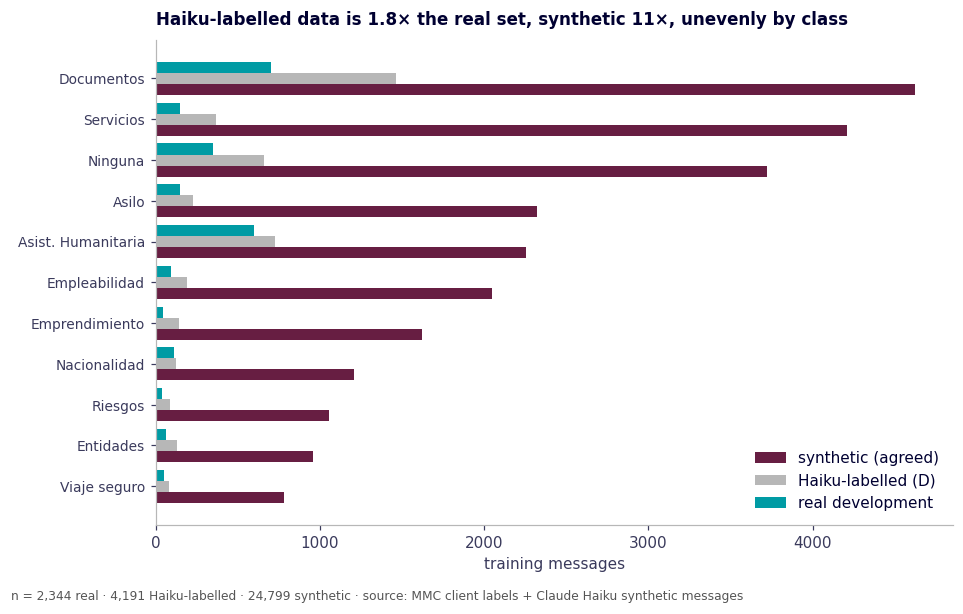

In [3]:
# --- Figure 1: training messages per class, by training set ---
order = counts.sort_values("Synthetic").index
fig, ax = plt.subplots(figsize=(8.8, 5.4))
yy = np.arange(len(order)); h = 0.27
for k, (col, colr, lab_) in enumerate([("Synthetic", theme.WINE, "synthetic (agreed)"), ("Haiku-labelled (D)", theme.GREY, "Haiku-labelled (D)"),
                                      ("Real dev", theme.TEAL, "real development")]):
    ax.barh(yy + (k - 1) * h, counts.loc[order, col], h, color=colr, label=lab_)
ax.set_yticks(yy, order, fontsize=9); ax.set_xlabel("training messages"); ax.legend(frameon=False, loc="lower right")
ax.set_title(f"Haiku-labelled data is {len(rows_d) / len(dev_idx):.1f}× the real set, synthetic {len(syn) / len(dev_idx):.0f}×, unevenly by class", loc="left", fontsize=11)
fig.text(0.01, -0.02, f"n = {len(dev_idx):,} real · {len(rows_d):,} Haiku-labelled · {len(syn):,} synthetic · {SRC}", fontsize=8, color="#555")
plt.tight_layout(); plt.show()

## 2 · Inside the synthetic data (expect it to be very high)

A classifier trained and tested **on synthetic messages only**, 5-fold cross-validation with folds grouped by
generation batch (the 25 messages of one batch share a prompt and are near-twins, so ungrouped folds would
inflate the score). The number says how *separable the generator's classes are*; it says nothing about how
good the messages are for real users. Real-only cross-validation (notebook 4's setting) is shown for contrast.

In [4]:
def cv_scores(X, yy, grp, folds):
    f1s, accs, t0 = [], [], time.perf_counter()
    for tr, va in folds:
        p = LinearSVC(C=2, class_weight="balanced").fit(X[tr], yy[tr]).predict(X[va])
        f1s.append(f1_score(yy[va], p, average="macro", labels=list(cz.CLASSES), zero_division=0))
        accs.append(accuracy_score(yy[va], p))
    return {"CV macro-F1": np.mean(f1s), "CV sd": np.std(f1s), "CV accuracy": np.mean(accs), "Time (s)": time.perf_counter() - t0}

syn_folds = list(StratifiedGroupKFold(5, shuffle=True, random_state=cz.CV_SEED).split(X_syn, y_syn, g_syn))
real_folds = cz.cv_folds(y[dev_idx], groups[dev_idx])
inside = pd.DataFrame({
    "Synthetic only (grouped by batch)": cv_scores(X_syn, y_syn, g_syn, syn_folds),
    "Real only (notebook 4's setting)": cv_scores(X_all[dev_idx], y[dev_idx], groups[dev_idx], real_folds),
}).T
inside.style.format({"CV macro-F1": "{:.3f}", "CV sd": "{:.3f}", "CV accuracy": "{:.1%}", "Time (s)": "{:.0f}"})

,CV macro-F1,CV sd,CV accuracy,Time (s)
Synthetic only (grouped by batch),0.988,0.002,98.8%,69
Real only (notebook 4's setting),0.735,0.023,82.5%,7


## 3 · Train on each variant, score on the frozen test

Four variants, fixed in advance, all with LinearSVC (C=2, balanced class weights) as in notebook 4:

| | Training data |
|---|---|
| **A · real only** | the development messages with the client's labels (notebook 4's baseline) |
| **B · synthetic only** | the agreed synthetic messages |
| **C · real + synthetic** | A and B together |
| **C′ · real + synthetic, synthetic ×0.25** | like C, with each synthetic message weighted 0.25 |
| **D · full Haiku-labelled dataset** | the final labels without the test set (real messages, labelled by Haiku + corrections) |

A logistic regression (balanced) is run on the same four as a check that the picture is not specific to the SVC.
Each variant is scored on the test set once. **Mixing real and synthetic is not tuned by cross-validation:** the
synthetic messages were seeded from the real development messages, so a validation message's paraphrases would
sit in the training fold and inflate the score. The test messages seeded nothing, so the test score is clean.

In [5]:
ARMS = {
    "A · real only":                       (X_all[dev_idx], y[dev_idx], None),
    "B · synthetic only":                  (X_syn, y_syn, None),
    "C · real + synthetic":                (np.vstack([X_all[dev_idx], X_syn]), np.r_[y[dev_idx], y_syn], None),
    "C′ · real + synthetic ×0.25":         (np.vstack([X_all[dev_idx], X_syn]), np.r_[y[dev_idx], y_syn],
                                            np.r_[np.ones(len(dev_idx)), np.full(len(syn), 0.25)]),
    "D · Haiku-labelled":                  (X_d, y_d, None),
}
MODELS = {
    "LinearSVC C=2":                 lambda: LinearSVC(C=2, class_weight="balanced"),
    "Logistic regression (balanced)": lambda: LogisticRegression(C=10, max_iter=2000, class_weight="balanced"),
}
Xt = X_all[test_idx]
CL = list(cz.CLASSES)
rows, preds = [], {}
for mname, make in MODELS.items():
    for aname, (Xa, ya, wa) in ARMS.items():
        t0 = time.perf_counter(); m = make().fit(Xa, ya, sample_weight=wa); fit_s = time.perf_counter() - t0
        t0 = time.perf_counter(); p = m.predict(Xt); pred_s = time.perf_counter() - t0
        preds[(mname, aname)] = p
        c = cz.scores(y[test_idx], p, CL)
        f = cz.scores(y_final[test_idx][has_final], p[has_final], CL)
        rows.append({"Model": mname, "Training data": aname, "Train rows": len(ya),
                     "Macro-F1": c["macro_f1"], "Macro-F1 (10 topics)": c["macro_f1_topics"], "Accuracy": c["accuracy"],
                     "Macro-F1, final labels": f["macro_f1"], "Accuracy, final labels": f["accuracy"],
                     "Fit (s)": fit_s, "Predict (s)": pred_s})
results = pd.DataFrame(rows)
results.style.format({"Train rows": "{:,}", "Macro-F1": "{:.3f}", "Macro-F1 (10 topics)": "{:.3f}", "Accuracy": "{:.1%}",
                      "Macro-F1, final labels": "{:.3f}", "Accuracy, final labels": "{:.1%}",
                      "Fit (s)": "{:.1f}", "Predict (s)": "{:.2f}"})

,Model,Training data,Train rows,Macro-F1,Macro-F1 (10 topics),Accuracy,"Macro-F1, final labels","Accuracy, final labels",Fit (s),Predict (s)
0,LinearSVC C=2,A · real only,"2,344",0.760,0.742,84.2%,0.719,80.0%,1.9,0.00
1,LinearSVC C=2,B · synthetic only,"24,799",0.496,0.489,58.2%,0.585,63.4%,18.3,0.01
2,LinearSVC C=2,C · real + synthetic,"27,143",0.673,0.648,80.3%,0.716,80.4%,21.8,0.00
3,LinearSVC C=2,C′ · real + synthetic ×0.25,"27,143",0.707,0.685,81.5%,0.730,80.9%,21.4,0.00
4,LinearSVC C=2,D · Haiku-labelled,"4,191",0.697,0.675,79.1%,0.771,82.9%,4.3,0.00
5,Logistic regression (balanced),A · real only,"2,344",0.737,0.717,81.1%,0.698,77.9%,21.6,0.02
6,Logistic regression (balanced),B · synthetic only,"24,799",0.532,0.524,61.2%,0.605,66.3%,24.4,0.02
7,Logistic regression (balanced),C · real + synthetic,"27,143",0.702,0.681,81.0%,0.713,79.9%,35.3,0.03
8,Logistic regression (balanced),C′ · real + synthetic ×0.25,"27,143",0.705,0.683,80.8%,0.710,79.5%,14.4,0.02
9,Logistic regression (balanced),D · Haiku-labelled,"4,191",0.687,0.665,77.7%,0.746,80.4%,27.1,0.01


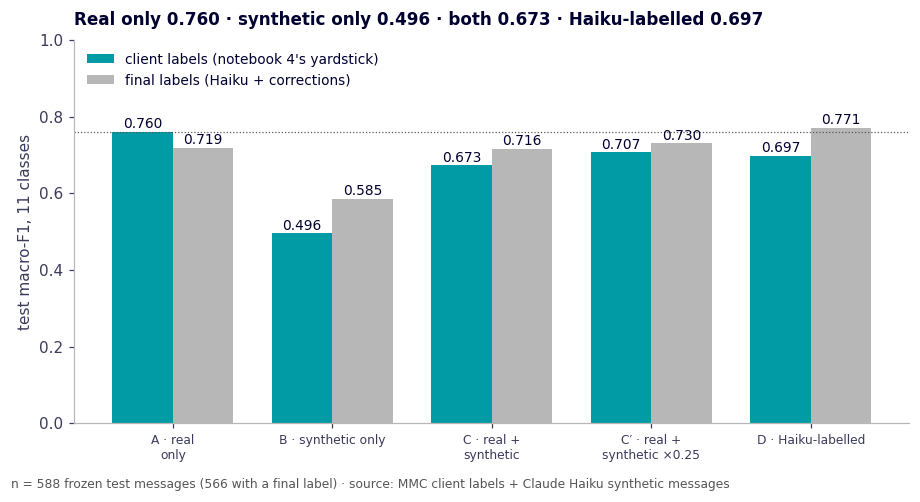

In [6]:
# --- Figure 2: macro-F1 on the frozen test, by training data (LinearSVC) ---
r = results[results["Model"] == "LinearSVC C=2"].reset_index(drop=True)
A_f1 = r.loc[0, "Macro-F1"]
x = np.arange(len(r)); w = 0.38
fig, ax = plt.subplots(figsize=(8.4, 4.4))
ax.bar(x - w / 2, r["Macro-F1"], w, color=theme.TEAL, label="client labels (notebook 4's yardstick)")
ax.bar(x + w / 2, r["Macro-F1, final labels"], w, color=theme.GREY, label="final labels (Haiku + corrections)")
for i in range(len(r)):
    ax.text(x[i] - w / 2, r.loc[i, "Macro-F1"] + 0.01, f"{r.loc[i, 'Macro-F1']:.3f}", ha="center", fontsize=9)
    ax.text(x[i] + w / 2, r.loc[i, "Macro-F1, final labels"] + 0.01, f"{r.loc[i, 'Macro-F1, final labels']:.3f}", ha="center", fontsize=9)
ax.set_xticks(x, [t.replace(" + ", " +" + chr(10)).replace("real only", "real" + chr(10) + "only") for t in r["Training data"]], fontsize=8); ax.set_ylim(0, 1); ax.set_ylabel("test macro-F1, 11 classes")
ax.axhline(A_f1, color="#555", lw=0.8, ls=":"); ax.legend(frameon=False, loc="upper left", fontsize=9)
ax.set_title(f"Real only {r.loc[0, 'Macro-F1']:.3f} · synthetic only {r.loc[1, 'Macro-F1']:.3f} · both {r.loc[2, 'Macro-F1']:.3f} · Haiku-labelled {r.loc[4, 'Macro-F1']:.3f}", loc="left", fontsize=11)
fig.text(0.01, -0.02, f"n = {len(test_idx)} frozen test messages ({int(has_final.sum())} with a final label) · {SRC}", fontsize=8, color="#555")
plt.tight_layout(); plt.show()

## 4 · Where synthetic data helps and where it hurts

Per-class F1 on the client-labelled test, each variant against the real-only baseline A. Classes with fewer than
15 test messages move by 0.05–0.1 for one message and are marked: read them as indicative only.

In [7]:
def per_class(p):
    rep = pd.DataFrame(classification_report(y[test_idx], p, labels=CL, output_dict=True, zero_division=0)).T.loc[CL]
    return rep["f1-score"].to_numpy(), rep["support"].astype(int).to_numpy()

M = "LinearSVC C=2"
f1 = {a: per_class(preds[(M, a)])[0] for a in ARMS}
support = per_class(preds[(M, "A · real only")])[1]
pc = pd.DataFrame(f1, index=[cz.SHORT[c] for c in CL])
pc.insert(0, "Test n", support)
for a in list(ARMS)[1:]:
    pc[f"Δ {a.split(' ·')[0]} vs A"] = pc[a] - pc["A · real only"]
pc["small class"] = np.where(pc["Test n"] < 15, "◂ <15", "")
pc.sort_values("Test n").round(2).style.format({"Δ B vs A": "{:+.2f}", "Δ C vs A": "{:+.2f}", "Δ C′ vs A": "{:+.2f}", "Δ D vs A": "{:+.2f}"})

,Test n,A · real only,B · synthetic only,C · real + synthetic,C′ · real + synthetic ×0.25,D · Haiku-labelled,Δ B vs A,Δ C vs A,Δ C′ vs A,Δ D vs A,small class
Riesgos,10,0.580000,0.120000,0.290000,0.440000,0.440000,-0.47,-0.30,-0.14,-0.14,◂ <15
Emprendimiento,12,0.880000,0.770000,0.770000,0.770000,0.710000,-0.11,-0.11,-0.11,-0.17,◂ <15
Viaje seguro,13,0.720000,0.000000,0.520000,0.640000,0.690000,-0.72,-0.20,-0.08,-0.03,◂ <15
Entidades,15,0.400000,0.310000,0.360000,0.360000,0.330000,-0.09,-0.04,-0.04,-0.07,
Empleabilidad,22,0.810000,0.650000,0.760000,0.760000,0.730000,-0.16,-0.05,-0.05,-0.08,
Nacionalidad,29,0.810000,0.620000,0.680000,0.750000,0.700000,-0.20,-0.13,-0.06,-0.11,
Asilo,37,0.830000,0.690000,0.840000,0.850000,0.870000,-0.14,+0.01,+0.02,+0.04,
Servicios,38,0.640000,0.540000,0.580000,0.560000,0.630000,-0.10,-0.06,-0.08,-0.01,
Ninguna,87,0.940000,0.560000,0.920000,0.920000,0.920000,-0.38,-0.02,-0.02,-0.02,
Asist. Humanitaria,149,0.850000,0.530000,0.820000,0.830000,0.780000,-0.32,-0.03,-0.02,-0.06,


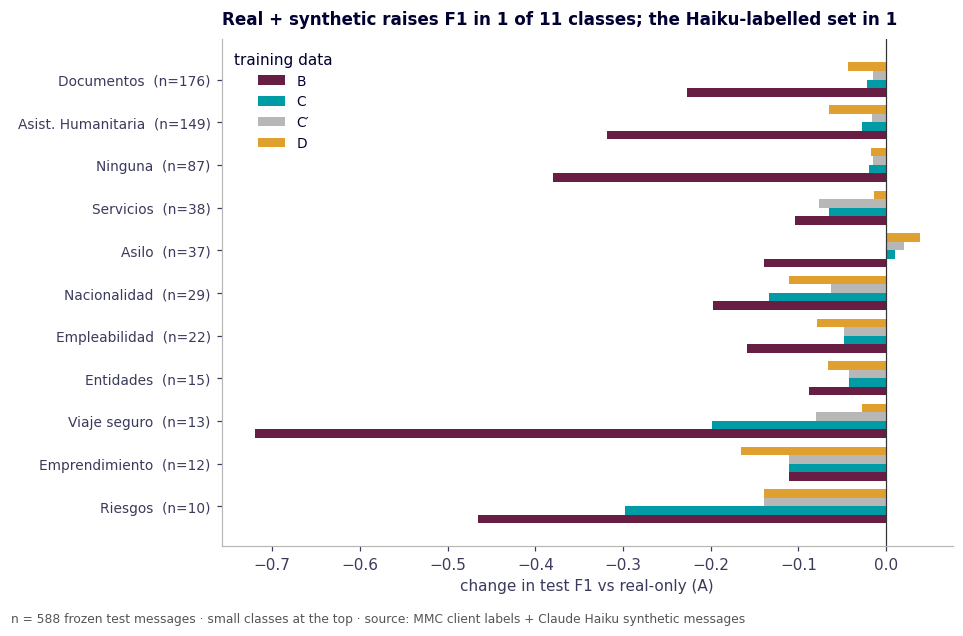

In [8]:
# --- Figure 3: change in per-class F1 against the real-only baseline ---
d = pc.sort_values("Test n")
fig, ax = plt.subplots(figsize=(8.8, 5.6))
yy = np.arange(len(d)); h = 0.2
for k, (col, colr) in enumerate([("Δ B vs A", theme.WINE), ("Δ C vs A", theme.TEAL), ("Δ C′ vs A", theme.GREY), ("Δ D vs A", "#e0a030")]):
    ax.barh(yy + (k - 1.5) * h, d[col], h, color=colr, label=col.replace("Δ ", "").replace(" vs A", ""))
ax.axvline(0, color="#333", lw=0.8)
ax.set_yticks(yy, [f"{n}  (n={s})" for n, s in zip(d.index, d["Test n"])], fontsize=9)
ax.set_xlabel("change in test F1 vs real-only (A)"); ax.legend(frameon=False, title="training data", fontsize=9)
gain = (d["Δ C vs A"] > 0).sum()
gain_d = (d["Δ D vs A"] > 0).sum()
ax.set_title(f"Real + synthetic raises F1 in {gain} of {len(d)} classes; the Haiku-labelled set in {gain_d}", loc="left", fontsize=11)
fig.text(0.01, -0.02, f"n = {len(test_idx)} frozen test messages · small classes at the top · {SRC}", fontsize=8, color="#555")
plt.tight_layout(); plt.show()

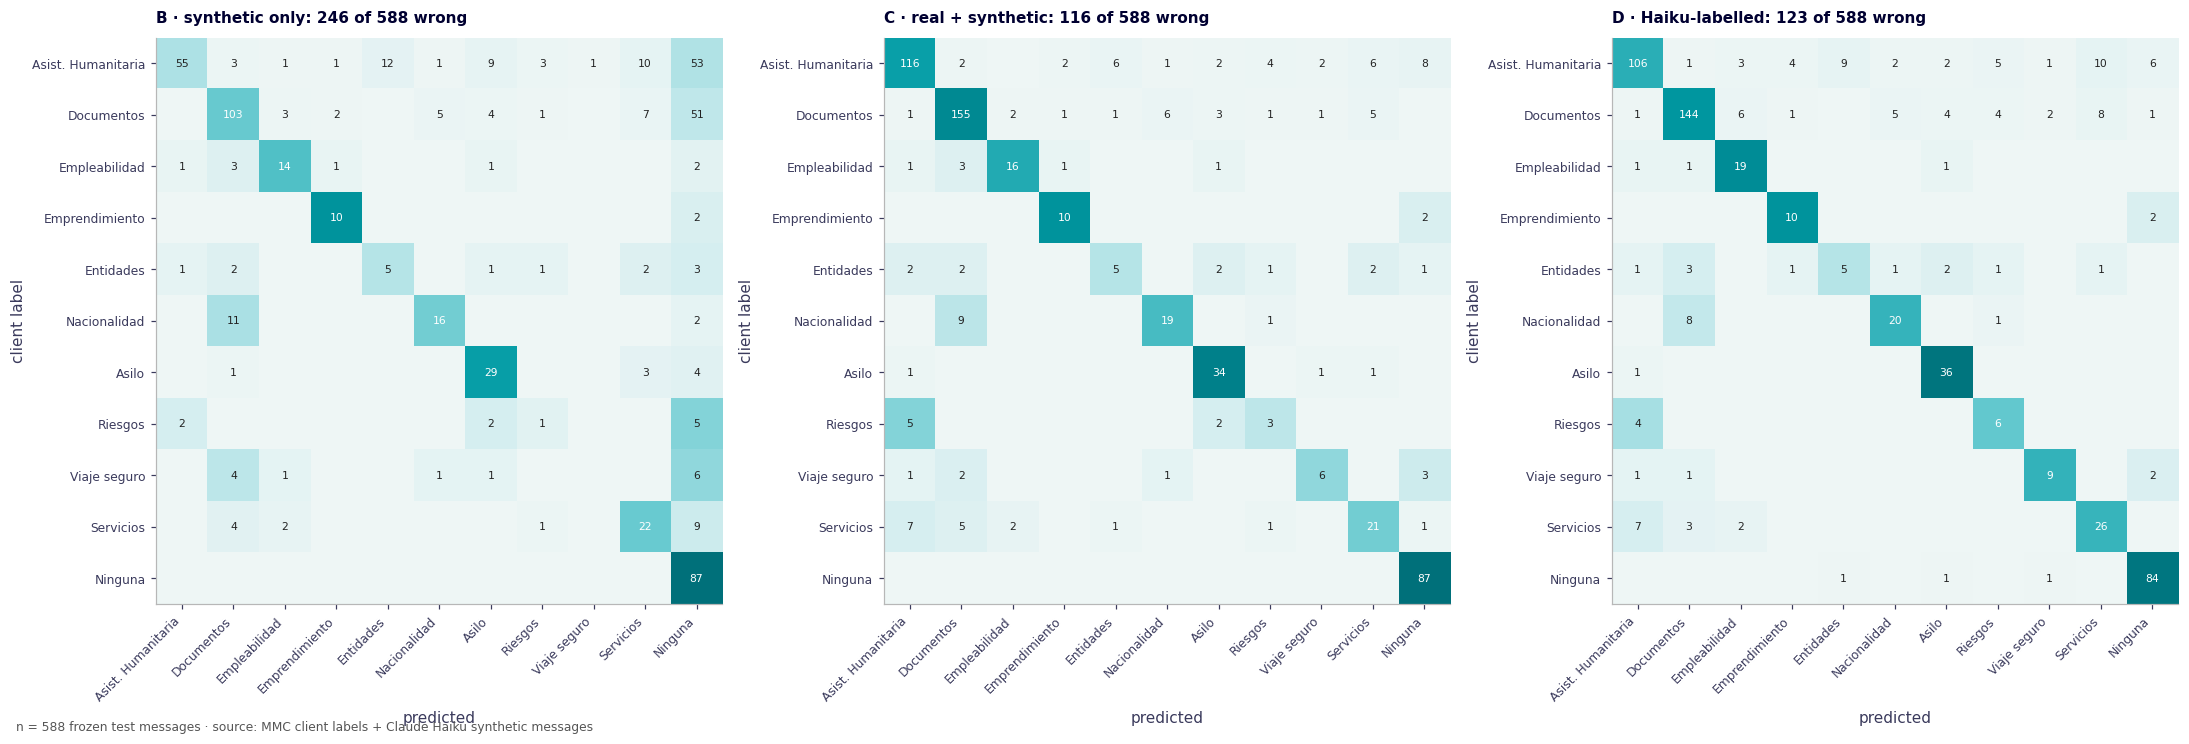

In [9]:
# --- Figure 4: confusion of B (synthetic only), C (real + synthetic) and D (Haiku-labelled), count per true class ---
short = [cz.SHORT[c] for c in CL]
fig, axes = plt.subplots(1, 3, figsize=(20, 6.6))
for ax, a in zip(axes, ["B · synthetic only", "C · real + synthetic", "D · Haiku-labelled"]):
    p = preds[(M, a)]
    cm = confusion_matrix(y[test_idx], p, labels=CL); cmn = cm / cm.sum(axis=1, keepdims=True)
    ax.imshow(cmn, cmap=theme.blue_cmap(), vmin=0, vmax=1)
    ax.set_xticks(range(len(short)), short, rotation=45, ha="right", fontsize=8); ax.set_yticks(range(len(short)), short, fontsize=8)
    for i in range(len(short)):
        for j in range(len(short)):
            if cm[i, j]:
                ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=7, color="white" if cmn[i, j] > 0.5 else "#222")
    ax.set_title(f"{a}: {int((p != y[test_idx]).sum())} of {len(test_idx)} wrong", loc="left", fontsize=10)
    ax.set_xlabel("predicted"); ax.set_ylabel("client label")
fig.text(0.01, 0.0, f"n = {len(test_idx)} frozen test messages · {SRC}", fontsize=8, color="#555")
plt.tight_layout(); plt.show()

In [10]:
# The most frequent mistakes as unordered pairs, for A, B, C and D.
def top_pairs(p, k=6):
    pairs = {}
    for t, q in zip(y[test_idx], p):
        if t != q:
            key = tuple(sorted((cz.SHORT[t], cz.SHORT[q]))); pairs[key] = pairs.get(key, 0) + 1
    s = pd.Series(pairs).sort_values(ascending=False).head(k)
    return pd.Series(s.values, index=[f"{a} ↔ {b}" for a, b in s.index])
pd.concat({a.split(" ·")[0]: top_pairs(preds[(M, a)]) for a in ["A · real only", "B · synthetic only", "C · real + synthetic", "D · Haiku-labelled"]}, axis=1).fillna(0).astype(int)

,A,B,C,D
Asist. Humanitaria ↔ Servicios,14,10,13,17
Documentos ↔ Nacionalidad,9,16,15,13
Documentos ↔ Servicios,8,11,10,11
Asist. Humanitaria ↔ Riesgos,7,0,9,9
Asist. Humanitaria ↔ Entidades,5,13,8,10
Asilo ↔ Documentos,5,0,0,0
Asist. Humanitaria ↔ Ninguna,0,53,8,0
Documentos ↔ Ninguna,0,51,0,0
Documentos ↔ Empleabilidad,0,0,0,7


## 5 · How much synthetic data is enough?

Variant C again with a growing share of the synthetic messages (the same share of every class, a fixed random
draw). Each point is one more fit scored once on the test set; **the curve is for shape only and no share is
chosen from it**. 0% is variant A and 100% is variant C, reused from §3.

In [11]:
rng = np.random.default_rng(0)
order_in_class = {c: rng.permutation(np.flatnonzero(y_syn == c)) for c in CL}
curve = []
for share in (0.0, 0.1, 0.25, 0.5, 1.0):
    if share in (0.0, 1.0):
        p = preds[(M, "A · real only" if share == 0 else "C · real + synthetic")]; n_syn = 0 if share == 0 else len(syn)
    else:
        pick = np.concatenate([order_in_class[c][: int(len(order_in_class[c]) * share)] for c in CL]); n_syn = len(pick)
        p = LinearSVC(C=2, class_weight="balanced").fit(np.vstack([X_all[dev_idx], X_syn[pick]]), np.r_[y[dev_idx], y_syn[pick]]).predict(Xt)
    s = cz.scores(y[test_idx], p, CL)
    curve.append({"Share of synthetic": share, "Synthetic rows": n_syn, "Macro-F1": s["macro_f1"], "Accuracy": s["accuracy"]})
curve = pd.DataFrame(curve)
curve.style.format({"Share of synthetic": "{:.0%}", "Synthetic rows": "{:,}", "Macro-F1": "{:.3f}", "Accuracy": "{:.1%}"})

,Share of synthetic,Synthetic rows,Macro-F1,Accuracy
0,0%,0,0.760,84.2%
1,10%,"2,476",0.736,83.3%
2,25%,"6,195",0.715,82.0%
3,50%,"12,398",0.701,81.0%
4,100%,"24,799",0.673,80.3%


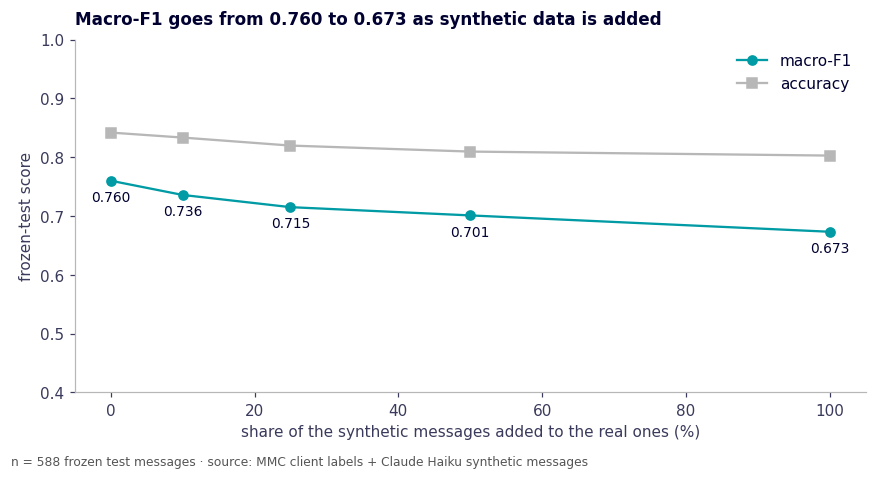

In [12]:
# --- Figure 5: test macro-F1 as synthetic data is added to the real data ---
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.plot(curve["Share of synthetic"] * 100, curve["Macro-F1"], "-o", color=theme.TEAL, label="macro-F1")
ax.plot(curve["Share of synthetic"] * 100, curve["Accuracy"], "-s", color=theme.GREY, label="accuracy")
for _, r_ in curve.iterrows():
    ax.text(r_["Share of synthetic"] * 100, r_["Macro-F1"] - 0.035, f"{r_['Macro-F1']:.3f}", ha="center", fontsize=9)
ax.set_xlabel("share of the synthetic messages added to the real ones (%)"); ax.set_ylabel("frozen-test score")
ax.set_ylim(0.4, 1); ax.legend(frameon=False)
ax.set_title(f"Macro-F1 goes from {curve['Macro-F1'].iloc[0]:.3f} to {curve['Macro-F1'].iloc[-1]:.3f} as synthetic data is added",
             loc="left", fontsize=11)
fig.text(0.01, -0.02, f"n = {len(test_idx)} frozen test messages · {SRC}", fontsize=8, color="#555")
plt.tight_layout(); plt.show()

## 6 · What this does and does not show

Computed from the cells above, so the sentences cannot drift from the numbers.

In [13]:
R = results.set_index(["Model", "Training data"])
g = lambda a, col="Macro-F1", m=M: R.loc[(m, a), col]
A_, B_, C_, Cp_, D_ = ("A · real only", "B · synthetic only", "C · real + synthetic", "C′ · real + synthetic ×0.25", "D · Haiku-labelled")
print(f"Inside the synthetic data (grouped CV): macro-F1 {inside.iloc[0]['CV macro-F1']:.3f} against {inside.iloc[1]['CV macro-F1']:.3f} on real data:")
print("  the generator's classes are far easier to tell apart than the real ones, as expected of synthetic text.")
print(f"On the frozen test (client labels), macro-F1: A {g(A_):.3f} · B {g(B_):.3f} · C {g(C_):.3f} · C′ {g(Cp_):.3f} · D {g(D_):.3f}.")
print(f"  Accuracy: A {g(A_, 'Accuracy'):.1%} · B {g(B_, 'Accuracy'):.1%} · C {g(C_, 'Accuracy'):.1%} · C′ {g(Cp_, 'Accuracy'):.1%} · D {g(D_, 'Accuracy'):.1%}.")
print(f"  Same on the final labels: A {g(A_, 'Macro-F1, final labels'):.3f} · B {g(B_, 'Macro-F1, final labels'):.3f} · C {g(C_, 'Macro-F1, final labels'):.3f} · C′ {g(Cp_, 'Macro-F1, final labels'):.3f} · D {g(D_, 'Macro-F1, final labels'):.3f}.")
lr = lambda a: g(a, m="Logistic regression (balanced)")
print(f"  Logistic regression gives A {lr(A_):.3f} · B {lr(B_):.3f} · C {lr(C_):.3f} · C′ {lr(Cp_):.3f} · D {lr(D_):.3f}: "
      + ("the same ordering." if np.argsort([lr(a) for a in (A_, B_, C_, Cp_, D_)]).tolist() == np.argsort([g(a) for a in (A_, B_, C_, Cp_, D_)]).tolist() else "a different ordering, so the SVC result is not general."))
small = pc[pc["Test n"] < 15].index.tolist()
print(f"Classes with fewer than 15 test messages ({', '.join(small)}) move by 0.05-0.1 per message: indicative only.")
print(f"Largest per-class gain of D over A: {pc['Δ D vs A'].idxmax()} ({pc['Δ D vs A'].max():+.2f}); largest loss: {pc['Δ D vs A'].idxmin()} ({pc['Δ D vs A'].min():+.2f}).")
print(f"Largest per-class gain of C over A: {pc['Δ C vs A'].idxmax()} ({pc['Δ C vs A'].max():+.2f}); largest loss: {pc['Δ C vs A'].idxmin()} ({pc['Δ C vs A'].min():+.2f}).")
print(f"Fit time: A {R.loc[(M, A_), 'Fit (s)']:.1f}s · D {R.loc[(M, D_), 'Fit (s)']:.1f}s · C {R.loc[(M, C_), 'Fit (s)']:.0f}s.")

Inside the synthetic data (grouped CV): macro-F1 0.988 against 0.735 on real data:
  the generator's classes are far easier to tell apart than the real ones, as expected of synthetic text.
On the frozen test (client labels), macro-F1: A 0.760 · B 0.496 · C 0.673 · C′ 0.707 · D 0.697.
  Accuracy: A 84.2% · B 58.2% · C 80.3% · C′ 81.5% · D 79.1%.
  Same on the final labels: A 0.719 · B 0.585 · C 0.716 · C′ 0.730 · D 0.771.
  Logistic regression gives A 0.737 · B 0.532 · C 0.702 · C′ 0.705 · D 0.687: a different ordering, so the SVC result is not general.
Classes with fewer than 15 test messages (Emprendimiento, Riesgos, Viaje seguro) move by 0.05-0.1 per message: indicative only.
Largest per-class gain of D over A: Asilo (+0.04); largest loss: Emprendimiento (-0.17).
Largest per-class gain of C over A: Asilo (+0.01); largest loss: Riesgos (-0.30).
Fit time: A 1.9s · D 4.3s · C 22s.


**Reading.**

- Variant A reproduces notebook 4 on the client's labels, so the comparison starts from the same baseline.
- Inside the synthetic data the classes are almost perfectly separable (§2), yet a model trained on synthetic
  messages alone does far worse on real ones (B). The synthetic text is easy to classify but does not look like
  the real messages closely enough to transfer; B's errors are mostly *Ninguna* mixed up with Asistencia
  Humanitaria and Documentos (§4).
- Adding synthetic messages to the real ones **lowers** the client-label test score, a little more with every
  share added (§5). Down-weighting them (C′) recovers part of the loss but stays below A.
- The **Haiku-labelled set (D)** has 1.8 times the real messages and scores **below A on the client's labels**
  (macro-F1 0.697 against 0.760, accuracy 79.1% against 84.2%), with the largest losses in the smallest classes
  (Emprendimiento, Riesgos). Against the **final labels** the picture flips: D is the best variant (0.771 against
  A's 0.719). The two views disagree because A learned the client's labelling convention and D learned Haiku's,
  which differs from the client's on the messages the human review looked at (it sided with Haiku in 306 of 328).
- So D is not a pure accuracy gain over A. Choosing between them is choosing which labels to reproduce: the
  client's, or the corrected Haiku labels. This notebook cannot settle that, because the final-label view is made
  of Haiku's own labels and therefore favours any training set Haiku labelled.
- Only the extremes are stable across the two models: A is the best variant on the client labels and B the worst
  with both the SVC and the logistic regression. The order of the middle variants (C, C′, D, within about 0.03)
  changes between them, so it should not be read as a ranking.


**Limits to keep in mind.**

- The test set is the same 588 messages as in notebook 4, so each variant's score carries the same sampling
  noise there (about one message per 0.2 percentage points of accuracy). Differences of a point or two between
  variants are inside that noise.
- The synthetic messages were written by one model from real development messages. They are cleaner and less
  varied than real chat, and their classes are by construction easier to separate (§2). A high score *inside*
  the synthetic set is not evidence about real messages.
- The **final** labels are Haiku's, from the same model family that wrote the synthetic messages and labelled D, so
  that view favours training on either. Read D's score there as agreement with Haiku's convention, not as independent
  evidence. The client-label view is independent of Haiku, but it carries the client's own label noise.
- Mixing is judged on the test set only, not by cross-validation (§3), so no mixing weight or share was tuned.
  The ×0.25 weight and the shares in §5 are shown side by side; none is picked as the winner here.